# Speed of `compare_pairs`

This notebook times `compare_pairs` on synthetic plates of several sizes, so you can see how long a comparison of your size takes.
The tables and plots are shown here and are not saved to disk.

**What is measured:** the wall-clock time of one call of `compare_pairs`, from the dataframe to the table of results.
That includes finding the pairs, computing the Pearson correlations, and building the table of results.

**Machine caveat:** the times depend on the computer that runs the notebook (its processor, the number of cores used by the matrix products of numpy, and its memory), so run the notebook on your machine to get your numbers.
The times of a first run can also be a little longer than the following ones.

In [1]:
import os
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pairwise_compare
from pairwise_compare import compare_pairs

warnings.filterwarnings("ignore")  # this notebook only times the function

print(f"Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, pairwise_compare {pairwise_compare.__version__}")
print(f"{platform.system()} {platform.machine()}, {os.cpu_count()} cores")

Python 3.12.7, numpy 2.5.4, pandas 3.1.1, pairwise_compare 0.1.4.dev2+g42591929f.d20261110
Darwin arm64, 8 cores


## Synthetic plates

The data look like the plates of an image-based profiling experiment.
Each plate has 72 wells, and the wells hold 18 cell lines with 4 replicate wells each.
Each well has the plate, the cell line and the well as metadata, followed by random features.

In [2]:
def make_plates(n_wells, n_features, seed=0):
    """A dataframe with `n_wells` wells (72 per plate, 18 cell lines of 4 wells) and `n_features` random features."""
    well = np.arange(n_wells)
    wells = pd.DataFrame(np.random.default_rng(seed).normal(size=(n_wells, n_features)), columns=[f"feature_{k}" for k in range(n_features)])
    wells["plate"] = well // 72
    wells["cell_line"] = (well % 72) // 4
    wells["well"] = well

    return wells


# the columns that define which wells are compared in each scenario: (same, different)
scenarios = {
    "replicates": (["plate", "cell_line"], ["well"]),  # the wells of the same cell line on the same plate
    "cross cell line": (["plate"], ["cell_line", "well"]),  # wells of different cell lines on the same plate
    "all pairs": ([], ["plate", "cell_line"]),  # wells of different plates and cell lines, with no column that must match
}

## Time it

Each call is timed with `time.perf_counter`, and the fastest of up to three runs is kept (a call that takes more than a second is run once).
The sizes are 100 to 57,600 wells and 100 to 5,000 features, with the number of values kept below 60 million so the data fit in memory.
The `all pairs` scenario compares every pair of wells with different plates and cell lines, which gives many more pairs, so it stops at 1,440 wells.

In [3]:
def time_call(wells, same, different):
    """The number of pairs and the fastest of up to three timings (in seconds) of one comparison."""
    features = [column for column in wells.columns if column.startswith("feature_")]
    best, n_pairs = np.inf, 0
    for _ in range(3):
        start = time.perf_counter()
        n_pairs = len(compare_pairs(wells, different=different, features=features, same=same))
        best = min(best, time.perf_counter() - start)
        if best > 1:
            break

    return n_pairs, best


runs = []
for n_wells in [100, 360, 1440, 5760, 14400, 57600]:
    for n_features in [100, 1000, 5000]:
        if n_wells * n_features > 60_000_000:
            continue
        wells = make_plates(n_wells, n_features)
        for scenario, (same, different) in scenarios.items():
            if scenario == "all pairs" and n_wells > 1440:
                continue
            n_pairs, seconds = time_call(wells, same, different)
            runs.append({"scenario": scenario, "wells": n_wells, "features": n_features, "pairs": n_pairs, "seconds": seconds})

runs = pd.DataFrame(runs)
print(f"{len(runs)} timings")

41 timings


## Seconds for each size

One table for each scenario, with the wells in the rows and the number of features in the columns.

In [4]:
for scenario, scenario_runs in runs.groupby("scenario", sort=False):
    print(f"{scenario}: seconds (and the number of pairs)")
    table = scenario_runs.pivot(index="wells", columns="features", values="seconds").round(3)
    table.insert(0, "pairs", scenario_runs.drop_duplicates("wells").set_index("wells")["pairs"])
    display(table.fillna(""))

replicates: seconds (and the number of pairs)


features,pairs,100,1000,5000
wells,,,,
100,150,0.005,0.013,0.054
360,540,0.006,0.016,0.058
1440,2160,0.011,0.029,0.119
5760,8640,0.030,0.087,0.438
14400,21600,0.071,0.179,
57600,86400,0.258,1.455,


cross cell line: seconds (and the number of pairs)


features,pairs,100,1000,5000
wells,,,,
100,2784,0.005,0.013,0.052
360,12240,0.007,0.017,0.058
1440,48960,0.015,0.029,0.116
5760,195840,0.076,0.124,0.522
14400,489600,0.206,0.283,
57600,1958400,0.818,1.560,


all pairs: seconds (and the number of pairs)


features,pairs,100,1000,5000
wells,,,,
100,1904,0.003,0.012,0.047
360,48960,0.010,0.021,0.063
1440,930240,0.176,0.192,0.319


## How the time grows

Left, the time against the number of pairs that are compared.
Right, the time against the number of wells for 1,000 features.
Both axes are logarithmic, so a straight line means the time grows in proportion to the size.

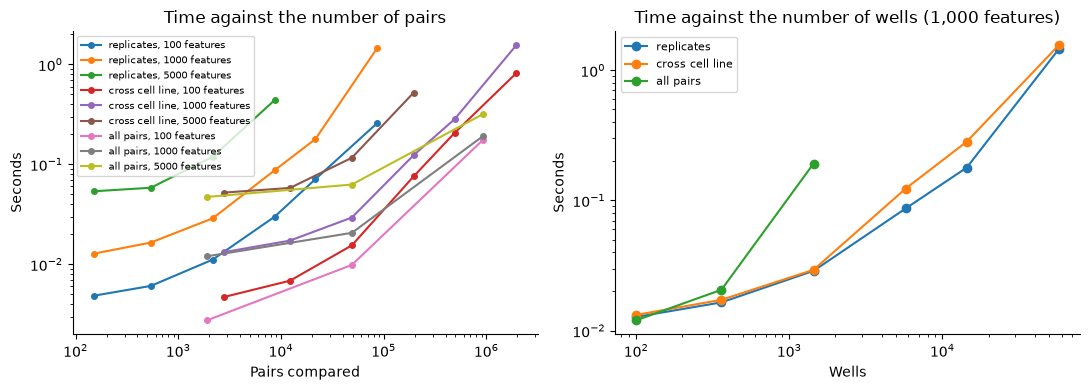

In [5]:
figure, (pairs_axis, wells_axis) = plt.subplots(1, 2, figsize=(11, 4))

for scenario, scenario_runs in runs.groupby("scenario", sort=False):
    for n_features, features_runs in scenario_runs.groupby("features"):
        pairs_axis.plot(features_runs["pairs"], features_runs["seconds"], "o-", ms=4, label=f"{scenario}, {n_features} features")
    thousand = scenario_runs[scenario_runs["features"] == 1000]
    wells_axis.plot(thousand["wells"], thousand["seconds"], "o-", label=scenario)

pairs_axis.set(xscale="log", yscale="log", xlabel="Pairs compared", ylabel="Seconds", title="Time against the number of pairs")
wells_axis.set(xscale="log", yscale="log", xlabel="Wells", ylabel="Seconds", title="Time against the number of wells (1,000 features)")
pairs_axis.legend(fontsize=7)
wells_axis.legend(fontsize=8)
for axis in (pairs_axis, wells_axis):
    axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout()
plt.show()

## Reading the results

The time depends on the number of pairs that are compared and on the number of features, not on how many groups the wells are split into.
The comparisons of replicates need few pairs, so they stay fast for large numbers of wells.
A scenario that compares many wells with each other (cross cell line, and especially all pairs) has many more pairs, and it takes longer in proportion.
The results table also grows with the number of pairs, so a comparison with many millions of pairs needs memory for its results.